# 01. ESM-2 임베딩 + linear probe (ProteinGym 변이 효과, 지도학습)

**등급**: 🟢 Mac 로컬 (MPS/CPU) · **예상 시간**: 5~10분 · **다운로드**: ESM-2 8M(31 MB)·35M(136 MB), ProteinGym v1.3 치환 데이터(43 MB)

**질문**: 고정된 ESM-2 임베딩 위에 선형 모델만 얹으면, 변이 효과(DMS 점수)를 **단순 baseline보다 잘** 예측하는가? 그리고 그 답은 **split 방식**에 따라 어떻게 달라지는가?

**설계**
- 데이터: ProteinGym의 DMS assay 2종, **단일 치환만** 사용. 높은 점수 = 높은 적합도로 정렬되어 있다†.
- 특징 5종
  - baseline: (B1) wt·mutant 아미노산 원-핫 + BLOSUM62 점수, (B2) B1 + **위치 원-핫**
  - ESM-2: (E1) 변이 서열의 평균 임베딩, (E2) 변이 위치의 임베딩, (E3) 변이 위치 임베딩 − wt 서열의 같은 위치 임베딩
- 모델: Ridge (규제 강도는 **train 안에서** 그룹 CV로, 보고 지표와 같은 **Spearman**을 기준으로 선택), 임베딩은 고정(linear probe)
- split 2종: **random**(변이 단위) vs **position-block**(연속 10개 위치 블록 단위로 test 위치를 통째로 분리)

> 모듈 01에서 배운 대로, random split은 같은 위치의 다른 변이가 train에 있어 낙관적일 수 있다. 이를 실제 데이터로 확인한다.

In [1]:
import os
import urllib.request
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)


def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "SETUP.md").exists():
            return q
    return None


ROOT = find_root()
if ROOT is not None:                                  # 저장소 안에서 실행: 캐시를 저장소 .cache/ (git 제외)에 둔다
    os.environ.setdefault("HF_HOME", str(ROOT / ".cache" / "hf"))   # 원하면 이 줄을 지워 기본 HF 캐시를 쓴다
DATA_DIR = (ROOT / ".cache" / "proteingym") if ROOT else Path("proteingym_data")   # Colab 등에서는 현재 폴더
DATA_DIR.mkdir(parents=True, exist_ok=True)

import torch
from scipy.stats import spearmanr
from transformers import AutoTokenizer, EsmForMaskedLM, EsmModel
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()      # EsmModel 로드 시 lm_head 가중치가 쓰이지 않는다는 안내 등을 숨김 (정상)
hf_logging.disable_progress_bar()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
print("device:", DEVICE, "| data dir:", DATA_DIR, "| HF_HOME:", os.environ.get("HF_HOME", "(default)"))

<repo>/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1110 11:42:58.548000 21383 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps | data dir: <repo>/.cache/proteingym | HF_HOME: <repo>/.cache/hf


## 1. 데이터 준비
ProteinGym v1.3 치환 DMS 데이터(약 43 MB)와 참조표를 내려받는다. 이미 있으면 건너뛴다.
출처: marks.hms.harvard.edu/proteingym (ProteinGym 공식 배포 위치).

In [2]:
PG_BASE = "https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/"
ZIP_PATH, REF_PATH = DATA_DIR / "DMS_ProteinGym_substitutions.zip", DATA_DIR / "DMS_substitutions.csv"
for fname, path in [("DMS_ProteinGym_substitutions.zip", ZIP_PATH), ("DMS_substitutions.csv", REF_PATH)]:
    if not path.exists():
        print("downloading", PG_BASE + fname)
        urllib.request.urlretrieve(PG_BASE + fname, path)
ref = pd.read_csv(REF_PATH)


def load_assay(dms_id):
    row = ref[ref.DMS_id == dms_id].iloc[0]
    with zipfile.ZipFile(ZIP_PATH) as z:
        df = pd.read_csv(z.open(f"DMS_ProteinGym_substitutions/{row.DMS_filename}"))
    df = df[~df.mutant.str.contains(":")].copy()                    # 단일 치환만
    df["wt"], df["pos"], df["mt"] = df.mutant.str[0], df.mutant.str[1:-1].astype(int), df.mutant.str[-1]
    assert all(row.target_seq[p - 1] == w for p, w in zip(df.pos, df.wt)), "wt 잔기가 target_seq와 다름"
    return row.target_seq, df.reset_index(drop=True), row


ASSAYS = ["UBC9_HUMAN_Weile_2017", "DN7A_SACS2_Tsuboyama_2023_1JIC"]
for a in ASSAYS:
    wt_seq, df, row = load_assay(a)
    print(f"{a:34s} len={len(wt_seq):4d}  singles={len(df):5d}  type={row.coarse_selection_type}/{row.selection_type}")

UBC9_HUMAN_Weile_2017              len= 159  singles= 2563  type=OrganismalFitness/complementation
DN7A_SACS2_Tsuboyama_2023_1JIC     len=  55  singles= 1008  type=Stability/cDNA display proteolysis


## 2. ESM-2 임베딩 추출
서열마다 (1) **평균 임베딩**(특수 토큰 `<cls>`, `<eos>`와 패딩을 제외한 잔기 위치의 평균), (2) **변이 위치의 임베딩**을 뽑는다.
토큰 인덱스 0은 `<cls>`이므로 잔기 위치 p(1부터 시작)는 토큰 인덱스 p에 해당한다.

In [3]:
ESM2 = {"8M": "facebook/esm2_t6_8M_UR50D", "35M": "facebook/esm2_t12_35M_UR50D"}


def load_esm(name):
    tok = AutoTokenizer.from_pretrained(name)
    model = EsmModel.from_pretrained(name, add_pooling_layer=False).to(DEVICE).eval()
    return tok, model


@torch.no_grad()
def embed(tok, model, seqs, positions, batch=64, layer=-1):
    """반환: 평균 임베딩 (N,d), 변이 위치 임베딩 (N,d). 평균에서 <cls>/<eos>/패딩 제외.
    layer: hidden_states 인덱스 (0 = 임베딩 층 출력, -1 = 마지막 층 = last_hidden_state).
    attention mask는 패딩만 걸러 주고 <cls>/<eos>는 mask=1이므로 아래에서 따로 제외한다."""
    means, sites = [], []
    for s in range(0, len(seqs), batch):
        enc = tok(list(seqs[s:s + batch]), return_tensors="pt", padding=True).to(DEVICE)
        out = model(**enc, output_hidden_states=(layer != -1))
        h = out.last_hidden_state if layer == -1 else out.hidden_states[layer]      # (b, T, d)
        m = enc["attention_mask"].clone()
        lengths = m.sum(1)
        m[:, 0] = 0                                             # <cls> 제외
        m[torch.arange(m.size(0)), lengths - 1] = 0             # <eos> 제외
        means.append(((h * m.unsqueeze(-1)).sum(1) / m.sum(1, keepdim=True)).cpu())
        pos = torch.as_tensor(positions[s:s + batch], device=DEVICE)
        sites.append(h[torch.arange(h.size(0)), pos].cpu())     # 잔기 위치 p ↔ 토큰 인덱스 p
    return torch.cat(means).numpy(), torch.cat(sites).numpy()


@torch.no_grad()
def wt_residue_embeddings(tok, model, wt_seq):
    enc = tok(wt_seq, return_tensors="pt").to(DEVICE)
    return model(**enc).last_hidden_state[0].cpu().numpy()      # (L+2, d)


# 빠른 정합성 확인: 서열 하나를 단독으로 넣을 때와 배치(패딩 포함)로 넣을 때 평균 임베딩이 같아야 한다
tok8, esm8 = load_esm(ESM2["8M"])
wt_seq, df, _ = load_assay(ASSAYS[0])
alone, _ = embed(tok8, esm8, [df.mutated_sequence[0]], [int(df.pos[0])])
mixed, _ = embed(tok8, esm8, [df.mutated_sequence[0], df.mutated_sequence[1][:100]], [int(df.pos[0]), 5])   # 두 번째는 짧아서 패딩됨
print("hidden size:", alone.shape[1], "| 패딩 유무에 따른 평균 임베딩 최대 차이:", float(np.abs(alone[0] - mixed[0]).max()))
n_layers = esm8.config.num_hidden_layers
last_idx, _ = embed(tok8, esm8, [df.mutated_sequence[0]], [int(df.pos[0])], layer=n_layers)     # hidden_states의 마지막 원소
mid, _ = embed(tok8, esm8, [df.mutated_sequence[0]], [int(df.pos[0])], layer=n_layers // 2)      # 중간 층 (과제 1에서 비교)
print(f"layer={n_layers}(마지막) vs 기본(-1) 최대 차이: {float(np.abs(last_idx - alone).max()):.1e} | 중간 층(layer={n_layers // 2})은 다른 값: {float(np.abs(mid - alone).max()):.2f}")

hidden size: 320 | 패딩 유무에 따른 평균 임베딩 최대 차이: 0.0
layer=6(마지막) vs 기본(-1) 최대 차이: 0.0e+00 | 중간 층(layer=3)은 다른 값: 7.70


## 3. baseline 특징과 split
- **B1**: wt 아미노산(20)과 mutant 아미노산(20)의 원-핫 + BLOSUM62(wt, mut) 점수다. 위치 정보는 없다.
- **B2**: B1 + 위치 원-핫이다. **위치별 평균 효과를 활용할 수 있어서**, 같은 위치의 다른 치환이 train에 있는 random split에서는 유리하다.
  position-block split에서는 test 위치의 원-핫 열이 train에서 전부 0이라 해당 계수가 0이 되어 위치 정보가 쓰이지 않는다. 다만 B1과 완전히 같지는 않다. train 위치 열이 aa 계수에 영향을 주기 때문이다.

In [4]:
from Bio.Align import substitution_matrices
from sklearn.linear_model import Ridge
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, ShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

AA = "ACDEFGHIKLMNPQRSTVWY"
BLOSUM = substitution_matrices.load("BLOSUM62")


def onehot(chars):
    M = np.zeros((len(chars), len(AA)))
    M[np.arange(len(chars)), [AA.index(c) for c in chars]] = 1
    return M


def baseline_features(df, L):
    blos = np.array([BLOSUM[w][m] for w, m in zip(df.wt, df.mt)], dtype=float)[:, None]
    B1 = np.hstack([onehot(df.wt), onehot(df.mt), blos])
    P = np.zeros((len(df), L))
    P[np.arange(len(df)), df.pos.values - 1] = 1
    return B1, np.hstack([B1, P])


def make_splits(df, kind, n=5, seed=0):
    if kind == "random":
        groups = np.arange(len(df))                                   # 변이 단위 (안쪽 CV도 변이 단위)
        it = ShuffleSplit(n_splits=n, test_size=0.2, random_state=seed).split(df)
    else:
        groups = (df.pos.values - 1) // 10                            # 연속 10개 위치 = 1 블록
        it = GroupShuffleSplit(n_splits=n, test_size=0.2, random_state=seed).split(df, groups=groups)
    return list(it), groups


def spearman_score(y_true, y_pred):
    r = spearmanr(y_true, y_pred).statistic
    return -1.0 if np.isnan(r) else r          # 예측이 상수이면 상관이 정의되지 않으므로 최저점으로 처리한다


def fit_eval(X, y, groups, tr, te):
    """규제 강도 alpha는 train 안에서 같은 방식의 그룹 CV로, 보고 지표와 같은 Spearman을 기준으로 고르고, test는 한 번만 본다.
    (GridSearchCV 기본 점수는 Ridge의 R²이므로 scoring을 명시하지 않으면 보고 지표와 다른 기준으로 alpha가 선택된다.)"""
    pipe = make_pipeline(StandardScaler(), Ridge())
    gs = GridSearchCV(pipe, {"ridge__alpha": np.logspace(0, 4, 9)}, cv=GroupKFold(n_splits=3), scoring=make_scorer(spearman_score))
    gs.fit(X[tr], y[tr], groups=groups[tr])
    return spearmanr(gs.predict(X[te]), y[te]).statistic

## 4. 실행 — 2 assay × 2 모델 × 2 split × 5 특징(baseline 2종은 모델과 무관) × 5 반복
오래 걸리면 `REPEATS`를 줄인다.

In [5]:
REPEATS = 5
records = []
for model_name in ["8M", "35M"]:
    tok, esm = (tok8, esm8) if model_name == "8M" else load_esm(ESM2[model_name])
    for assay in ASSAYS:
        wt_seq, df, row = load_assay(assay)
        y = df.DMS_score.values
        mean_emb, site_emb = embed(tok, esm, df.mutated_sequence.tolist(), df.pos.tolist())
        wt_h = wt_residue_embeddings(tok, esm, wt_seq)
        site_delta = site_emb - wt_h[df.pos.values]                      # 변이 위치의 (변이 문맥 − wt 문맥) 임베딩 차이
        B1, B2 = baseline_features(df, len(wt_seq))
        feats = {"B1 aa+BLOSUM": B1, "B2 B1+position": B2, "E1 mean emb": mean_emb, "E2 site emb": site_emb, "E3 site delta": site_delta}
        for kind in ["random", "position-block"]:
            splits, groups = make_splits(df, kind, n=REPEATS, seed=SEED)
            for fname, X in feats.items():
                if fname.startswith("B") and model_name != "8M":
                    continue                                              # baseline은 모델과 무관하므로 한 번만 계산한다
                rhos = [fit_eval(X, y, groups, tr, te) for tr, te in splits]
                records.append(dict(assay=assay.split("_")[0], model=("-" if fname.startswith("B") else model_name),
                                    split=kind, feature=fname, rho=np.mean(rhos), sd=np.std(rhos)))
res = pd.DataFrame(records)
print("done:", len(res), "rows")

done: 32 rows


## 5. 결과 — test Spearman (5회 반복 평균 ± 표준편차)

In [6]:
def fmt(r):
    return f"{r.rho:5.2f}±{r.sd:4.2f}"


for assay in res.assay.unique():
    sub = res[res.assay == assay].copy()
    sub["cell"] = sub.apply(fmt, axis=1)
    sub["row"] = sub.model + " " + sub.feature
    print(f"\n=== {assay} ===")
    print(sub.pivot(index="row", columns="split", values="cell").to_string())


=== UBC9 ===
split             position-block      random
row                                         
- B1 aa+BLOSUM         0.28±0.04   0.42±0.03
- B2 B1+position       0.30±0.03   0.70±0.01
35M E1 mean emb        0.22±0.04   0.56±0.01
35M E2 site emb        0.15±0.07   0.63±0.01
35M E3 site delta      0.15±0.07   0.56±0.03
8M E1 mean emb         0.22±0.07   0.53±0.01
8M E2 site emb         0.18±0.05   0.57±0.02
8M E3 site delta       0.13±0.05   0.52±0.01

=== DN7A ===
split             position-block      random
row                                         
- B1 aa+BLOSUM         0.58±0.05   0.70±0.02
- B2 B1+position       0.56±0.05   0.81±0.03
35M E1 mean emb        0.57±0.09   0.80±0.02
35M E2 site emb        0.43±0.09   0.83±0.03
35M E3 site delta      0.49±0.09   0.79±0.02
8M E1 mean emb         0.52±0.13   0.74±0.03
8M E2 site emb         0.46±0.09   0.81±0.02
8M E3 site delta       0.44±0.04   0.75±0.04


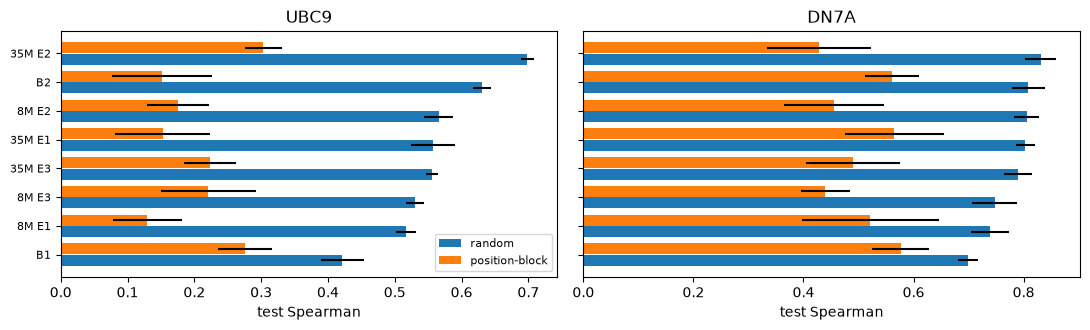

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(res.assay.unique()), figsize=(11, 3.4), sharey=True)
for ax, assay in zip(np.atleast_1d(axes), res.assay.unique()):
    sub = res[res.assay == assay]
    sub = sub.assign(label=sub.model.replace("-", "") + " " + sub.feature.str.split().str[0])
    order = sub[sub.split == "random"].sort_values("rho").label.tolist()
    for off, kind, c in [(-0.2, "random", "tab:blue"), (0.2, "position-block", "tab:orange")]:
        s = sub[sub.split == kind].set_index("label").loc[order]
        ax.barh(np.arange(len(order)) + off, s.rho, height=0.38, xerr=s.sd, color=c, label=kind)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=8)
    ax.set_title(assay)
    ax.set_xlabel("test Spearman")
np.atleast_1d(axes)[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. 비교: 라벨 없는 zero-shot 점수 1개를 특징으로 쓰면?
임베딩(수백 차원)을 쓰는 대신, ESM-2 35M의 **masked marginal 점수 하나**(다음 노트북에서 자세히 다룬다)를 특징으로 쓴다.
비교 대상: (Z) 점수 하나만, (B1+Z) 점수 + B1. 같은 split·같은 Ridge 절차를 쓴다. 학습 없이 점수 자체만 쓴 Spearman도 함께 본다.

In [8]:
AAS = "ACDEFGHIKLMNPQRSTVWY"


@torch.no_grad()
def masked_marginal_scores(tok, mlm, seq, df, batch=32):
    ids = tok(seq, return_tensors="pt")["input_ids"][0]
    aa_ids = torch.tensor(tok.convert_tokens_to_ids(list(AAS)), device=DEVICE)
    L = len(seq)
    table = np.zeros((L, len(AAS)), dtype=np.float32)
    for st in range(0, L, batch):
        idx = torch.arange(st, min(st + batch, L))
        b = ids.unsqueeze(0).repeat(len(idx), 1)
        b[torch.arange(len(idx)), idx + 1] = tok.mask_token_id
        lg = mlm(input_ids=b.to(DEVICE)).logits
        lp = torch.log_softmax(lg[torch.arange(len(idx)), (idx + 1).to(DEVICE)].float(), dim=-1)
        table[idx.numpy()] = lp[:, aa_ids].cpu().numpy()
    p = df.pos.values - 1
    return table[p, [AAS.index(m) for m in df.mt]] - table[p, [AAS.index(w) for w in df.wt]]


tok35 = AutoTokenizer.from_pretrained(ESM2["35M"])
mlm35 = EsmForMaskedLM.from_pretrained(ESM2["35M"]).to(DEVICE).eval()
zrec = []
for assay in ASSAYS:
    wt_seq, df, row = load_assay(assay)
    y = df.DMS_score.values
    z = masked_marginal_scores(tok35, mlm35, wt_seq, df)[:, None]
    B1, _ = baseline_features(df, len(wt_seq))
    zrec.append(dict(assay=assay.split("_")[0], split="(학습 없음)", feature="Z zero-shot 점수 그대로", rho=spearmanr(z[:, 0], y).statistic, sd=np.nan))
    for kind in ["random", "position-block"]:
        splits, groups = make_splits(df, kind, n=REPEATS, seed=SEED)
        for fname, X in {"Z (1 feature)": z, "B1+Z": np.hstack([B1, z])}.items():
            rhos = [fit_eval(X, y, groups, tr, te) for tr, te in splits]
            zrec.append(dict(assay=assay.split("_")[0], split=kind, feature=fname, rho=np.mean(rhos), sd=np.std(rhos)))
zres = pd.DataFrame(zrec)
for assay in zres.assay.unique():
    sub = zres[zres.assay == assay].copy()
    sub["cell"] = sub.apply(lambda r: f"{r.rho:5.2f}" + ("" if np.isnan(r.sd) else f"±{r.sd:4.2f}"), axis=1)
    print(f"\n=== {assay} (zero-shot 점수 기반) ===")
    print(sub.pivot(index="feature", columns="split", values="cell").to_string())


=== UBC9 (zero-shot 점수 기반) ===
split              (학습 없음) position-block      random
feature                                              
B1+Z                   NaN      0.27±0.05   0.44±0.03
Z (1 feature)          NaN     -0.03±0.09   0.01±0.03
Z zero-shot 점수 그대로    0.00            NaN         NaN

=== DN7A (zero-shot 점수 기반) ===
split              (학습 없음) position-block      random
feature                                              
B1+Z                   NaN      0.60±0.04   0.74±0.02
Z (1 feature)          NaN      0.19±0.04   0.21±0.07
Z zero-shot 점수 그대로    0.21            NaN         NaN


**'Z 그대로'와 'Z (1 feature)'가 다른 이유**: 전자는 학습 없이 **전체 데이터**에서 점수와 DMS의 Spearman을 잰 값이고, 후자는 점수를 Ridge에 넣어 **test split 20%**에서 잰 값의 5회 평균이다.
특징이 하나뿐이면 Ridge는 `w·z + b`라서 w > 0이면 순위는 z와 같고 w < 0이면 뒤집힌다. 상관이 0 근처이면(UBC9) split에 따라 w의 부호가 바뀔 수 있어 평균이 0 근처에서 흔들린다.

## 7. 해석 가이드
이 실행(seed=0, 2 assay)에서 확인한 패턴을 아래에 적는다. **숫자는 직접 다시 확인하고**, 다른 assay나 블록 크기에서는 달라질 수 있다.

- **위치 원-핫(B2)은 split에 따라 효과가 크게 다르다.** random split에서 B1에서 B2로 가면 점수가 크게 오르지만(UBC9 약 0.42에서 0.70으로) position-block split에서는 거의 오르지 않는다(약 0.28에서 0.30으로).
  같은 위치의 다른 치환이 train에 있어 위치별 평균 효과를 활용할 수 있기 때문이라는 해석과 일치하는 관찰이다(**가설**이며 직접 증명한 것은 아니다). 새 위치를 예측하는 것이 목표라면 random split 점수는 낙관적이고, "이미 측정된 위치의 미측정 치환을 채우는 것"이 목표라면 의도된 설정일 수 있다.
- **ESM-2 임베딩 probe가 baseline을 항상 이기지는 않는다.** UBC9에서는 position-block split의 ESM 특징(약 0.13~0.22)이 B1(0.28)보다 낮았고, DN7A에서는 평균 임베딩(E1, 35M 0.57)이 B1(0.58)과 비슷했다. 훈련 샘플이 1~2.5천 개이고 임베딩이 320~480차원인 설정에서 선형 probe가 고차원 표현을 다 활용하지 못했을 수 있다. 규제 강도, 층 선택, 샘플 수를 바꿔 확인하는 것이 과제 1이다.
- **평균 임베딩(E1)은 변이 한 개를 길이 전체로 평균해 신호가 희석된다.** 변이 위치 임베딩(E2, E3)이 더 직접적이지만 이 실험에서 일관되게 낫지는 않았다.
- **35M zero-shot 점수 1개(6절)는 이 두 assay에서 도움이 크지 않았다.** UBC9에서는 점수 자체의 Spearman이 0.00 근처, DN7A에서는 약 0.21이고 B1+Z는 B1과 거의 같다(UBC9 0.27/0.44 vs 0.28/0.42, DN7A 0.60/0.74 vs 0.58/0.70). 작은 모델의 zero-shot은 쓸모가 제한적일 수 있다. 다음 노트북에서 모델 크기별로 확인하며, UBC9는 150M부터 약 0.4로 오른다.
- 표준편차는 **분할 반복 변동**이다(5회). assay 2개로 일반 결론을 내지 않는다.

## 8. 한계와 과제
- **assay 2개·위치 블록 크기 10**에서의 결과다. 블록 크기, 마스크 비율, 층 선택(`embed(..., layer=)`)을 바꾸면 달라질 수 있다.
- 이 노트북의 probe는 **지도학습**(DMS 점수 일부로 학습)이다. 라벨 없이 점수를 만드는 zero-shot은 다음 노트북에서 다룬다.
- 과제: [../exercises.md](../exercises.md) 과제 1 (모듈 산출물).